In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [3]:
df=pd.read_csv('youtube-sentiment-90k.csv')
df.head()

,CommentText,Sentiment
0,My loop isn't stopping in VS Code.,Negative
1,That's not even a hundred feet😂,Negative
2,The people in Palisades didn’t sit around and ...,Negative
3,"God,I know the reporter is stressed but she ca...",Negative
4,Gavin Newsom and Karen Bass the Trudeau's of C...,Negative


In [4]:
df.shape

(90000, 2)

In [7]:
df.duplicated().sum()

np.int64(1669)

In [8]:
df['Sentiment'].value_counts()

Sentiment
Negative    30000
Neutral     30000
Positive    30000
Name: count, dtype: int64

In [9]:
df.isnull().sum()

CommentText    0
Sentiment      0
dtype: int64

In [10]:
df = df.rename(columns={"CommentText": "text", "Sentiment": "label"})

print(df.isnull().sum())
df = df.dropna()
df = df.drop_duplicates()

# also drop same text with conflicting labels (bad for training)
conflict = df.groupby("text")["label"].nunique()
conflict = conflict[conflict > 1].index
print("conflicting-label texts:", len(conflict))
df = df[~df["text"].isin(conflict)]

print(df.shape)
print(df["label"].value_counts())

text     0
label    0
dtype: int64
conflicting-label texts: 108
(88114, 2)
label
Negative    29786
Neutral     29340
Positive    28988
Name: count, dtype: int64


count    88114.000000
mean        19.749904
std         33.010300
min          0.000000
25%          7.000000
50%         12.000000
75%         22.000000
max       1697.000000
Name: n_words, dtype: float64


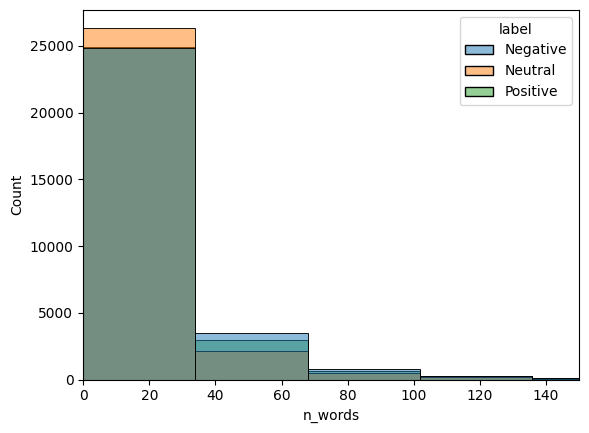

has non-ascii: 0.28326940100324577

 Negative
["The whole situation sounds like a combination of GameStop's pricing and Best Buy's lack of product knowledge and selection.", 'The solutions suggesting a min-heap seem to overlook the fact that this specific solution is designed to run with O(1) memory usage. A heap requires additional memory.', "great explanation, but there's a small bug, in your drawn cycle, it should start with 0 -> 1 -> 3, or you can start with 1 - > 3, but then slow and fast should both set to nums[0] initially.", 'Nope that crap needs to be addressed like now get his supvisir on the phone thats your stuff he is tress passing', 'I don’t believe any man on CNN who’s knees are sore']

 Neutral
['Horsey', 'I knew it was redbull', 'And they just watch COCOMELON 💀', 'ബോച്ചേയുടെ വസ്ത്രധാരണവുമായി ഒന്ന് താരതമ്യം ചെയ്യണം. പിന്നെ കുന്തി ദേവിക്ക് എന്താണ് പ്രശ്നം. എന്താണ് കുന്തി ദേദേവിക്ക് കൊള്ളരുതായ്മ കുഴപ്പം', 'Anyone watching this in 2032?']

 Positive
['This is why us "minor

In [11]:
df["n_words"] = df["text"].str.split().str.len()
print(df["n_words"].describe())

sns.histplot(data=df, x="n_words", hue="label", bins=50, log_scale=(False, False))
plt.xlim(0, 150)
plt.show()

# how many contain emojis / non-ASCII
print("has non-ascii:", df["text"].str.contains(r"[^\x00-\x7F]").mean())

# look at a few examples per class
for lab in ["Negative", "Neutral", "Positive"]:
    print("\n", lab)
    print(df[df["label"] == lab]["text"].sample(5, random_state=1).tolist())

In [13]:
import re
import emoji

def preprocess(text: str) -> str:
    text = str(text)
    text = text.replace("’", "'").replace("‘", "'")     # curly -> straight apostrophes
    text = emoji.demojize(text, delimiters=(" ", " "))   # 😂 -> "face_with_tears_of_joy"
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)          # URLs
    text = re.sub(r"[^a-z0-9'_\s!?]", " ", text)         # keep ! and ? as they carry sentiment
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean"] = df["text"].apply(preprocess)
df = df[df["clean"].str.len() > 0]
df[["text", "clean"]].head(10)

,text,clean
0,My loop isn't stopping in VS Code.,my loop isn't stopping in vs code
1,That's not even a hundred feet😂,that's not even a hundred feet face_with_tears...
2,The people in Palisades didn’t sit around and ...,the people in palisades didn't sit around and ...
3,"God,I know the reporter is stressed but she ca...",god i know the reporter is stressed but she ca...
4,Gavin Newsom and Karen Bass the Trudeau's of C...,gavin newsom and karen bass the trudeau's of c...
5,She’s an embarrassment. Crazy Nancy,she's an embarrassment crazy nancy
6,"jesus fuckign hell man, that better be some pr...",jesus fuckign hell man that better be some pre...
7,I think any team is a reflection of the manage...,i think any team is a reflection of the manage...
8,Humans will be out of jobs if robots can do ev...,humans will be out of jobs if robots can do ev...
9,Liverpool won absolutely nothing.,liverpool won absolutely nothing


In [14]:
from sklearn.model_selection import train_test_split

label_map = {"Negative": 0, "Neutral": 1, "Positive": 2}
df["y"] = df["label"].map(label_map)

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["y"], test_size=0.2, stratify=df["y"], random_state=42
)
print(X_train.shape, X_test.shape)

(69872,) (17468,)


accuracy: 0.6723150904511106
macro-F1: 0.6732754077228439
              precision    recall  f1-score   support

    Negative       0.65      0.69      0.67      5907
     Neutral       0.62      0.63      0.62      5796
    Positive       0.76      0.70      0.73      5765

    accuracy                           0.67     17468
   macro avg       0.68      0.67      0.67     17468
weighted avg       0.67      0.67      0.67     17468



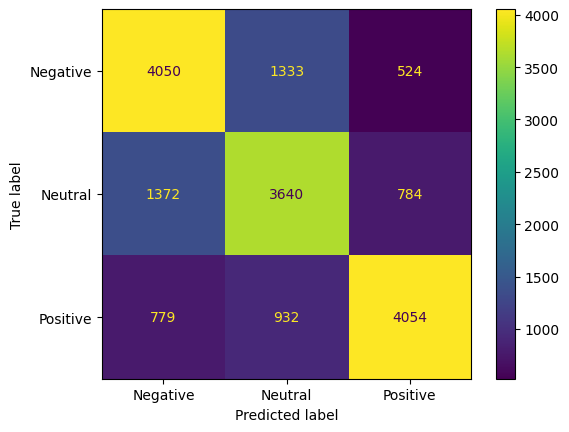

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score, accuracy_score, ConfusionMatrixDisplay

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20000, min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, C=1.0)),
])

pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)

print("accuracy:", accuracy_score(y_test, pred))
print("macro-F1:", f1_score(y_test, pred, average="macro"))
print(classification_report(y_test, pred, target_names=list(label_map)))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=list(label_map))
plt.show()

In [19]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
import pandas as pd

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def run(name, pipe):
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    print(f"{name:35s} macro-F1 = {scores.mean():.4f} ± {scores.std():.4f}")
    return {"name": name, "f1": scores.mean()}

results = []

# 1. vectorizer variations with logistic regression
for ngram in [(1,1), (1,2), (1,3)]:
    for maxf in [20000, 50000]:
        p = Pipeline([("tfidf", TfidfVectorizer(ngram_range=ngram, max_features=maxf, min_df=2, sublinear_tf=True)),
                      ("clf", LogisticRegression(max_iter=1000, C=2.0))])
        results.append(run(f"LR tfidf ngram={ngram} feats={maxf}", p))

# 2. different models on the same features
tfidf = lambda: TfidfVectorizer(ngram_range=(1,2), max_features=50000, min_df=2, sublinear_tf=True)
results.append(run("LinearSVC", Pipeline([("t", tfidf()), ("clf", LinearSVC(C=0.5))])))
results.append(run("ComplementNB", Pipeline([("t", tfidf()), ("clf", ComplementNB())])))

# 3. word + character n-grams (handles typos, slang, elongated words)
union = FeatureUnion([
    ("word", TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True)),
    ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2,5), min_df=3, sublinear_tf=True)),
])
results.append(run("LR word+char", Pipeline([("u", union), ("clf", LogisticRegression(max_iter=1000, C=2.0))])))

pd.DataFrame(results).sort_values("f1", ascending=False)

LR tfidf ngram=(1, 1) feats=20000   macro-F1 = 0.6516 ± 0.0031
LR tfidf ngram=(1, 1) feats=50000   macro-F1 = 0.6514 ± 0.0037
LR tfidf ngram=(1, 2) feats=20000   macro-F1 = 0.6581 ± 0.0005
LR tfidf ngram=(1, 2) feats=50000   macro-F1 = 0.6648 ± 0.0020
LR tfidf ngram=(1, 3) feats=20000   macro-F1 = 0.6575 ± 0.0011
LR tfidf ngram=(1, 3) feats=50000   macro-F1 = 0.6632 ± 0.0010
LinearSVC                           macro-F1 = 0.6600 ± 0.0007
ComplementNB                        macro-F1 = 0.6392 ± 0.0015
LR word+char                        macro-F1 = 0.6760 ± 0.0002


,name,f1
8,LR word+char,0.675992
3,"LR tfidf ngram=(1, 2) feats=50000",0.664783
5,"LR tfidf ngram=(1, 3) feats=50000",0.663244
6,LinearSVC,0.659960
2,"LR tfidf ngram=(1, 2) feats=20000",0.658069
4,"LR tfidf ngram=(1, 3) feats=20000",0.657450
0,"LR tfidf ngram=(1, 1) feats=20000",0.651570
1,"LR tfidf ngram=(1, 1) feats=50000",0.651445
7,ComplementNB,0.639236


In [20]:
err = pd.DataFrame({"text": X_test, "true": y_test, "pred": pred})
inv = {v: k for k, v in label_map.items()}
err = err[err.true != err.pred]
for _, r in err.sample(15, random_state=0).iterrows():
    print(f"[true={inv[r.true]:8s} pred={inv[r.pred]:8s}] {r.text[:150]}")

[true=Positive pred=Neutral ] pls accept linfire300 pls thats me
[true=Negative pred=Positive] she is very attractive
[true=Neutral  pred=Positive] since i started using boosteroid my gaming experience has improved dramatically highly recommend
[true=Negative pred=Neutral ] pray for gaza and humanity palestinian_territories palestinian_territories
[true=Negative pred=Neutral ] it's an edit lol face_with_tears_of_joy
[true=Neutral  pred=Negative] it's only on the internet that individuals feel compelled to present a perfect image when achieving this perfection becomes the primary goal the envir
[true=Negative pred=Positive] they covered up such beauty
[true=Negative pred=Neutral ] let ten through but will at least snitch on one lol cold move
[true=Neutral  pred=Negative] i attempted to solve this problem using a dummy node keeping everything else the same but it didn't give the correct solution is it not possible to so
[true=Positive pred=Neutral ] react by far is best to learn as there